# Spatial Wetlands Insight Tool <img align="right" src="../Supplementary_data/dea_logo.jpg">

* [**Sign up to the DEA Sandbox**](https://knowledge.dea.ga.gov.au/guides/setup/Sandbox/sandbox/) to run this notebook interactively from a browser
* **Compatibility:** Notebook currently compatible with `DEA Sandbox` environment only
* **Products used:**
[ga_ls5t_ard_3](https://explorer.dea.ga.gov.au/products/ga_ls5t_ard_3),
[ga_ls7e_ard_3](https://explorer.dea.ga.gov.au/products/ga_ls7e_ard_3),
[ga_ls8c_ard_3](https://explorer.dea.ga.gov.au/products/ga_ls8c_ard_3),
[ga_ls9c_ard_3](https://explorer.dea.ga.gov.au/products/ga_ls9c_ard_3),
[ga_ls_wo_3](https://explorer.dea.ga.gov.au/products/ga_ls_wo_3),
[ga_ls_fc_3](https://explorer.dea.ga.gov.au/products/ga_ls_fc_3)

## Background

The [DEA Wetlands Insight Tool](https://knowledge.dea.ga.gov.au/data/category/dea-wetlands-insight-tool/) (WIT) summarises water, wet vegetation, green vegetation, dry vegetation and bare soil across a wetland polygon and plots their fractions as a stacked timeseries. Consistent Landsat data is available from 1987, so the tool can place recent conditions against several decades of history.

Because the fractions are summarised over the whole polygon, the result is a single value per class per date. That tells you how much of the wetland was water, but not which part of it. Spatial WIT keeps the same classification and retains it per pixel, producing a categorical map for every satellite observation. Those maps make some questions easier to approach: which parts of a wetland hold water in most years rather than only in large floods, where vegetation persists through a dry period, or whether a change visible in the timeseries is happening across the whole wetland or in one part of it.

The same caveats apply as for the timeseries tool – see [Dunn et al. 2023](https://doi.org/10.1007/s13157-023-01682-7) for the method and its limitations.

### Description

This notebook demonstrates the spatial WIT functions in `dea_tools.wetlands`:

1. Run the WIT over a polygon to produce the underlying data cube
2. Classify it spatially, using either a simple or a detailed class scheme
3. Plot individual observations for a short period
4. Export the classified maps as GeoTIFFs for use in a GIS
5. Summarise the maps by season, showing both the typical class and how consistent it is
6. Animate the maps, on their own and alongside the WIT timeseries

In [1]:
import sys

sys.path.insert(0, "../Tools/")

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Video

import datacube
from dea_tools.wetlands import (
    WIT_drill,
    animate_wit,
    animate_wit_with_timeseries,
    display_wit_stack_with_df,
    plot_wit_season_year,
    plot_wit_seasonal_climatology,
    plot_wit_timesteps,
    spatial_wit,
    wit_seasonal_composites,
    write_class_geotiffs,
    draw_polygon,
    polygon_from_map
)

In [2]:
# def show(path, width=800):
#     """Display an animation, whichever format it was written in."""
#     if path.endswith(".mp4"):
#         return Video(path, embed=True, width=width)
#     return Image(path, width=width)

## Analysis parameters

* `time`: the period to analyse.
* `poly`: the wetland of interest.

### Time

In [3]:
time = ("2013-12-01", "2015-11-30")

### Option 1: load a polygon
Load your own file into the Sandbox and update the path (`poly`). The polygon must be in EPSG:3577 ([GDA94 Australian Albers](https://epsg.io/3577)) and contain 2D geometry only – remove any "z" coordinates first.

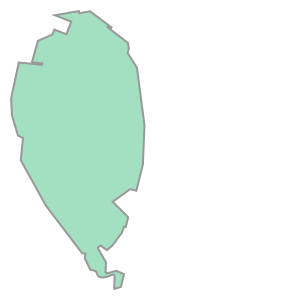

In [4]:
polygon_name = "Hird Swamp"
poly = gpd.read_file("../Supplementary_data/DEA_Wetlands_Insight_Tool/hird.shp")
poly.geometry[0]

### Option 2: draw a polygon

If you don't have a polygon file, draw one instead. Run the cell below, use the polygon or rectangle tool on the left of the map, then run the cell after it to convert what you drew.

A mapped wetland boundary will usually be more defensible than a hand-drawn outline, particularly if you intend to report the results. Drawing is best for exploring.

In [5]:
# m = draw_polygon()
# m

In [6]:
# poly = polygon_from_map(m)
# poly.geometry[0]

## Run the Wetlands Insight Tool

`WIT_drill` loads Landsat, Water Observations and Fractional Cover, calculates Tasseled Cap Wetness, and combines them into the five WIT classes. It returns an `xarray.Dataset` holding one value per class per pixel per observation, along with the polygon-wide timeseries used for the standard WIT plot. For details on this workflow, please see the [Introduction to the DEA Wetlands Insight Tool](../DEA_products/DEA_Wetlands_Insight_Tool.ipynb) notebook.

Note that not every satellite pass produces a usable observation. Landsat 7 imagery from the SLC-off period is excluded, observations missing from any of the three products are dropped, and any observation where more than 10% of the polygon is cloud, shadow or missing data is discarded entirely.

This cell does the bulk of the work and may take several minutes.

In [7]:
%%time
ds_wit, polygon_base_df = WIT_drill(poly, time=time)

print(f"{ds_wit.sizes['time']} usable observations")
print(f"grid: {ds_wit.sizes['y']} x {ds_wit.sizes['x']} pixels")

Finding datasets
    ga_ls9c_ard_3
    ga_ls8c_ard_3
    ga_ls7e_ard_3 (ignoring SLC-off observations)
    ga_ls5t_ard_3
Applying fmask pixel quality/cloud mask
Returning 89 time steps as a dask array
Dropping bands ['nbart_blue', 'nbart_green', 'nbart_red', 'nbart_nir', 'nbart_swir_1', 'nbart_swir_2']
85 usable observations
grid: 127 x 62 pixels
CPU times: user 3min 25s, sys: 54.4 s, total: 4min 19s
Wall time: 4min 45s


For reference, here is the standard WIT timeseries plot for this polygon. Everything that follows is a spatial view of the same data.

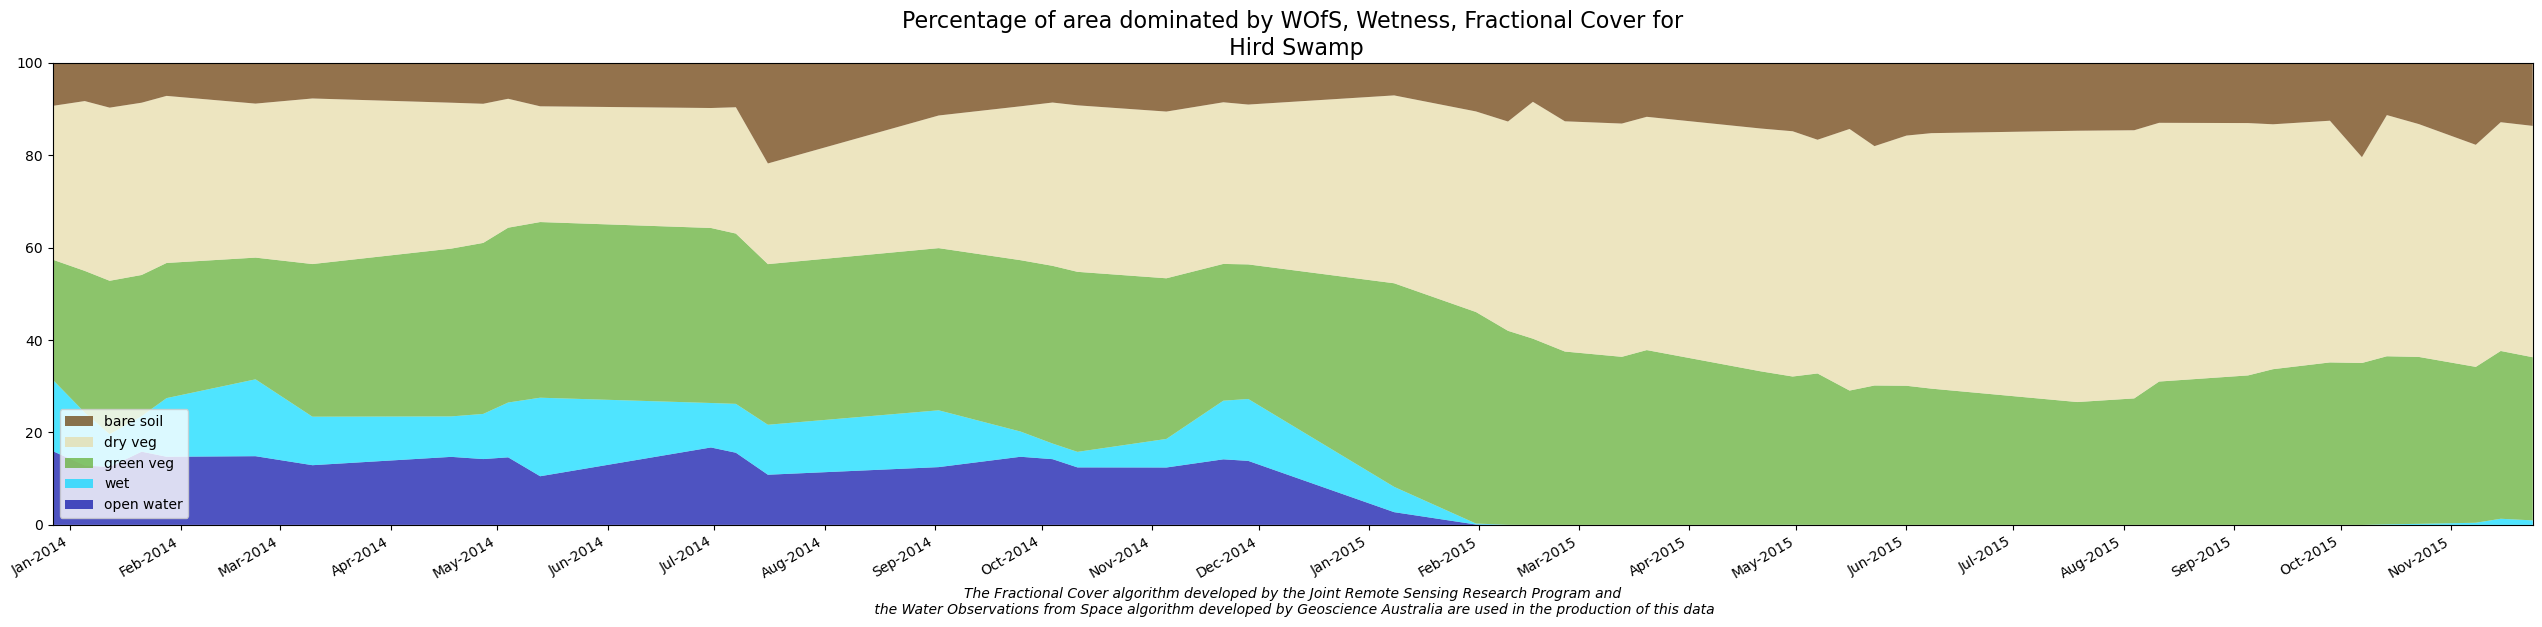

In [8]:
display_wit_stack_with_df(
    polygon_base_df, polygon_name, png_name=polygon_name, x_axis_labels="months"
)

## Spatial classification

`spatial_wit` renormalises the fractional cover components so they sum to 1 in each pixel, then assigns a class based on which components dominate it. Wet and water come from the Tasseled Cap Wetness and Water Observations classifications and are not fractional, so they override the cover class where present.

Two schemes are available:

* `"simple"` – three fractional cover classes plus wet and water. Easier to read, and directly comparable with the five bands of the timeseries plot.
    * `0` dry veg
    * `1` bare soil
    * `2` green veg
    * `3` wet 
    * `4` water
* `"detailed"` – the nine-class fractional cover breakdown (pure classes plus mixes) plus wet and water. More information, but harder to interpret at a glance.
    * `0` dry veg only
    * `1` dry veg and bare soil
    * `2` dry veg dominant
    * `3` dry veg and green veg
    * `4` bare soil only
    * `5` bare soil dominant
    * `6` bare soil and green veg
    * `7` green veg dominant
    * `8` green veg only
    * `9` wet
    * `10` water

In both schemes, pixels outside the polygon or masked as cloud are written as `255` in exported GeoTIFFs.

The function returns the classified `xarray.Dataset` and a `WITScheme` object carrying the class codes, labels and colours. Pass that scheme to every plotting function so the colours stay consistent.

In [9]:
ds_spatial, scheme = spatial_wit(ds_wit, scheme="simple")
ds_detailed, scheme_detailed = spatial_wit(ds_wit, scheme="detailed")

print(f"{ds_spatial.sizes['time']} observations classified")

47 observations classified


The follow cell plots the same observation under both schemes. The detailed scheme separates mixed pixels that the simple scheme assigns to whichever component is largest, which shows gradual transitions more clearly.

Pixels with all three components at exactly one third have no dominant component and are left unclassified in the detailed scheme. This is rare.

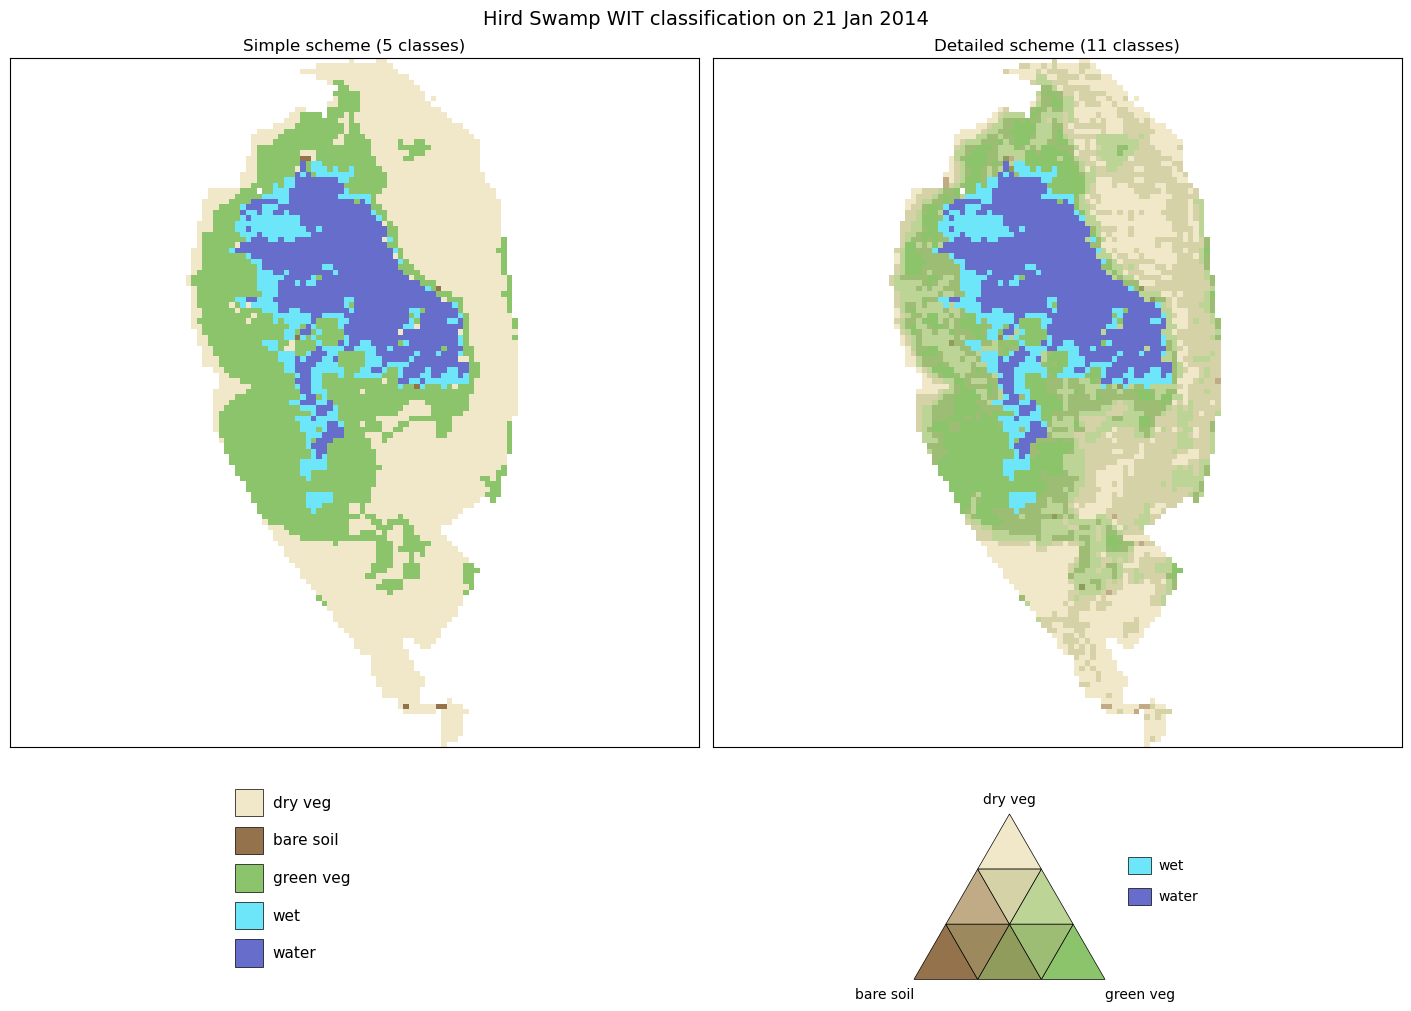

In [10]:
t = 3  

fig = plt.figure(figsize=(14, 10), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[4, 1.2])

for col, (ds, sch, name) in enumerate([
    (ds_spatial, scheme, "Simple scheme"),
    (ds_detailed, scheme_detailed, "Detailed scheme"),
]):
    ax_map = fig.add_subplot(gs[0, col])
    ds["wetland"].isel(time=t).plot.imshow(
        cmap=sch.cmap, norm=sch.norm, ax=ax_map, add_colorbar=False
    )
    ax_map.set_title(f"{name} ({len(sch.labels)} classes)")
    ax_map.set_aspect("equal")
    ax_map.set_box_aspect(1)
    ax_map.set_xlabel(""); ax_map.set_ylabel("")
    ax_map.set_xticks([]); ax_map.set_yticks([])

    ax_leg = fig.add_subplot(gs[1, col])
    sch.draw_legend(ax_leg, orientation="vertical")

date = pd.to_datetime(ds_spatial.time.values[t]).strftime("%d %b %Y")
fig.suptitle(f"{polygon_name} WIT classification on {date}", fontsize=14)
plt.show()

## Plot individual observations

`plot_wit_timesteps` draws one panel per observation. It is for short periods – a flood, a watering action, a single season – where each observation is worth looking at individually. 

Adjust the slice below to a period of interest.

10 observations in window


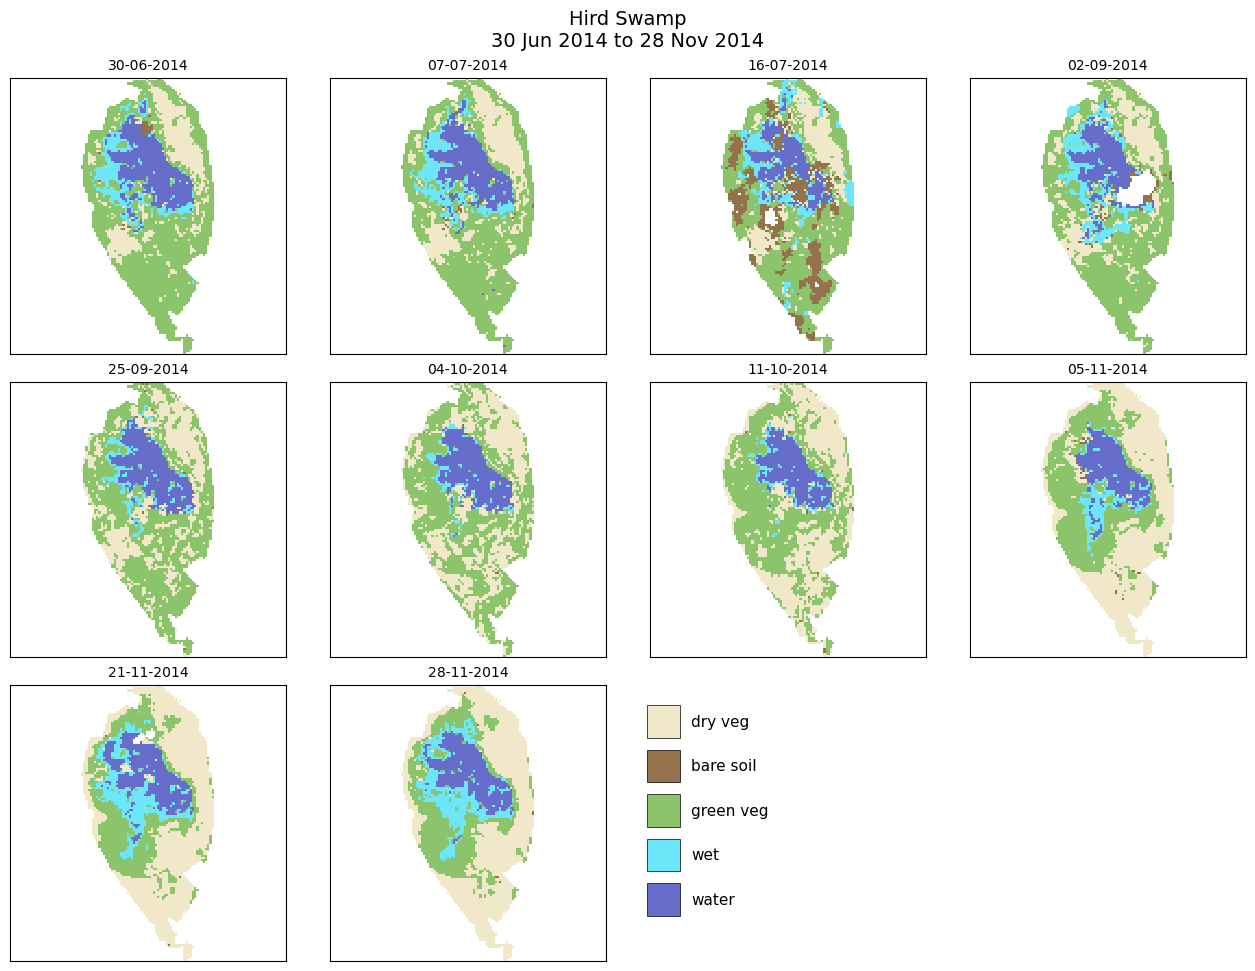

In [11]:
window = ds_spatial["wetland"].sel(time=slice("2014-06-01", "2014-12-01"))
print(f"{window.sizes['time']} observations in window")

fig = plot_wit_timesteps(window, scheme, title=polygon_name)
plt.show()

## Export to GeoTIFF

`write_class_geotiffs` writes one uint8 GeoTIFF per observation, with class codes as pixel values and 255 marking pixels outside the polygon or masked as cloud. The files carry the projection of the input data, EPSG:3577 by default, and load directly into QGIS or ArcGIS.

In [12]:
paths = write_class_geotiffs(
    ds_spatial["wetland"].isel(time=slice(0, 3)),
    output_dir="geotiffs",
    prefix=polygon_name.replace(" ", "_").lower(),
)

for p in paths:
    print(p)

# All observations – uncomment to export the full set
# paths = write_class_geotiffs(
#     ds_spatial["wetland"],
#     output_dir="geotiffs",
#     prefix=polygon_name.replace(" ", "_").lower(),
# )

geotiffs/hird_swamp_2013-12-27.tif
geotiffs/hird_swamp_2014-01-05.tif
geotiffs/hird_swamp_2014-01-12.tif


## Summarise by season

A single observation shows the wetland on one day. Whether that day was typical is hard to tell from the map alone. Pooling observations by season gives a more stable picture, and makes it possible to compare one season against another or the same season across years.

`wit_seasonal_composites` produces two summaries:

* **Season-year** – each season of each year separately, showing how a particular summer or winter behaved.
* **Climatology** – all summers pooled, all winters pooled, and so on, showing typical behaviour in each season.

For both it reports the **modal** class (the most frequent) and its **purity** (the share of clear observations that fell in that class). These must be read together. A pixel with 3 water and 2 dry observations has a modal class of water at a purity of 0.6 — the map will show it as confidently water, and only the purity tells you the observations were nearly split.

`min_obs` sets how many clear observations a season-year pixel needs before it is reported at all. `min_obs_clim` does the same for the climatology; over a two-year record it is set to 1 here, but over a full record a higher value is appropriate to exclude pixels that are almost always cloud-affected.

In [13]:
sc = wit_seasonal_composites(
    ds_spatial["wetland"], scheme, min_obs=3, min_obs_clim=1
)

assert list(sc.clim_modal.season.values) == ["DJF", "MAM", "JJA", "SON"]

print(f"{sc.sizes['time']} season-years, "
      f"{int(sc.season_year[0])}–{int(sc.season_year[-1])}")

8 season-years, 2014–2015


### Season by year

Rows are years and columns are seasons, so reading down a column shows how one season changed across the record, and reading across a row shows one year's annual cycle.

Blank cells are seasons where too few clear observations were available.

Clear observations per season (min_obs = 3):
  2014:  DJF 6   MAM 5   JJA 3   SON 7
  2015:  DJF 5   MAM 7   JJA 5   SON 9

Observations per month, whole record:
  Jan 6  Feb 4  Mar 3  Apr 4  May 5  Jun 3  Jul 3  Aug 2  Sep 5  Oct 5  Nov 6  Dec 1



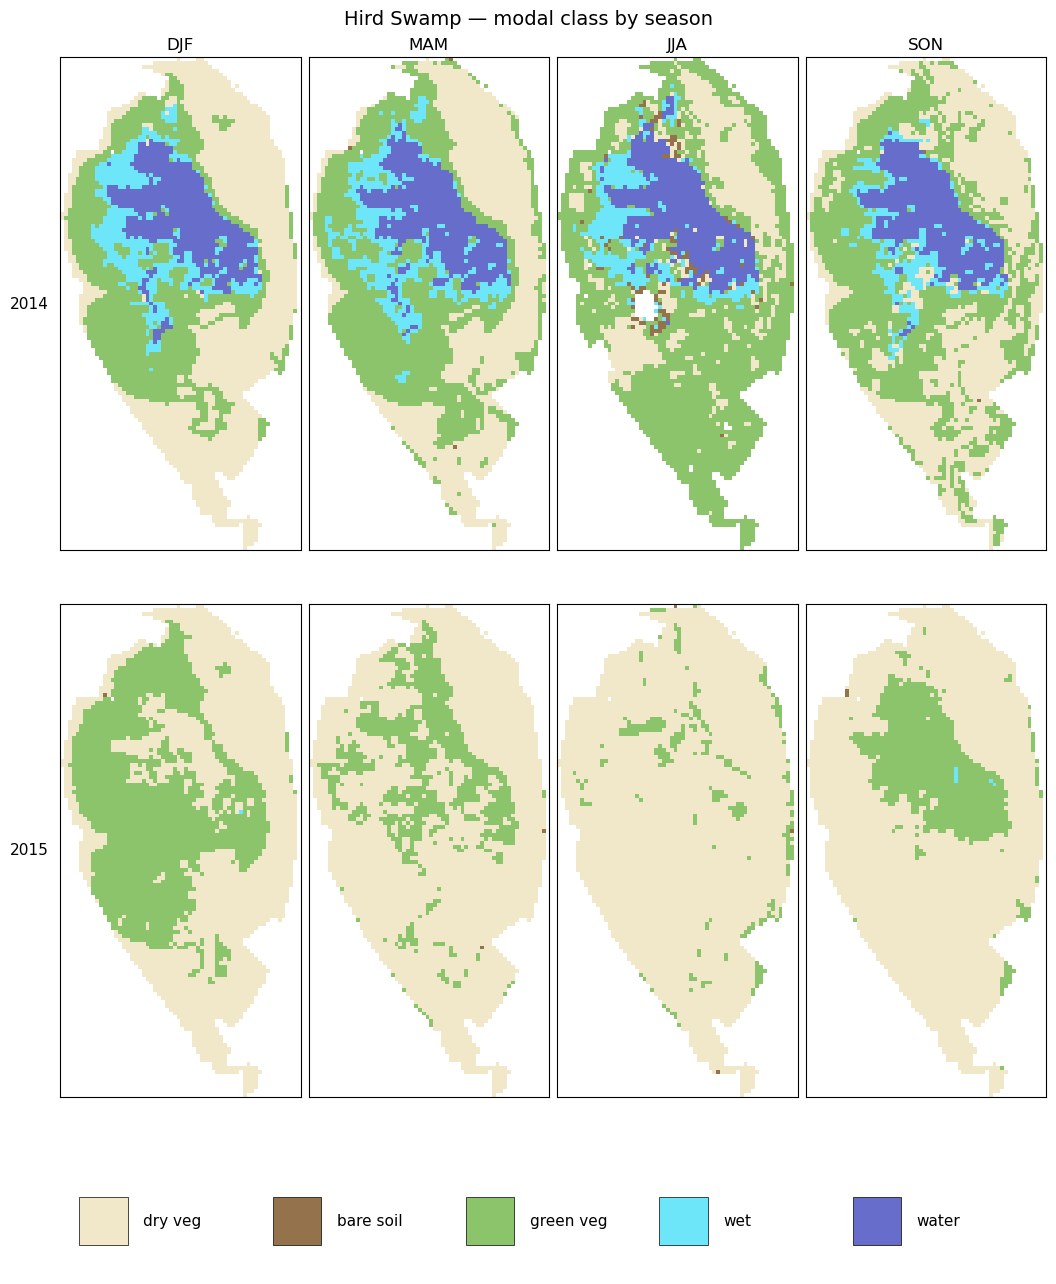

In [14]:
fig = plot_wit_season_year(
    sc, scheme,
    years=["2014", "2015"],
    da=ds_spatial["wetland"],
    title=f"{polygon_name} — modal class by season",
)
plt.show()

In [15]:
import inspect
print(inspect.signature(dea_tools.wetlands.plot_wit_season_year))

NameError: name 'dea_tools' is not defined

### Seasonal climatology

The top row shows the most likely class in each season; the bottom row shows how consistent that class was.

Dark areas in the purity row mark where the top row should not be trusted. A pixel can have a confident-looking class at a purity barely above chance, which means the observations were split and the class shown is close to arbitrary.

Two years is not a climatology in any meaningful sense — it demonstrates the function but says little about the wetland. Over a full record, pooling three decades of each season gives a genuinely useful picture of where a wetland reliably holds water.

In [ ]:
fig = plot_wit_seasonal_climatology(
    sc, scheme, title=f"{polygon_name} — seasonal climatology, {time[0][:4]}–{time[1][:4]}"
)
plt.show()

## Animate

`animate_wit` steps through the classified maps in time. It writes MP4 where ffmpeg is available and GIF otherwise.

Use `limit` for a quick check before committing to a full record — a few hundred frames takes a while to render.

In [ ]:
map_path = animate_wit(
    ds_spatial,
    scheme,
    output_path=f"{polygon_name.replace(' ', '_')}_animation",
    limit=20,
)
print(map_path)
show(map_path, width=600)

### Map and timeseries together

`animate_wit_with_timeseries` puts the classified map beside the WIT stack plot, with a cursor marking the frame being shown. This ties the spatial pattern to the summary statistic: a rise in the water fraction on the right can be traced to where the water appeared on the left.

Both inputs must come from the same `WIT_drill` call — the function checks this, because a cursor that does not match the map would be misleading rather than merely wrong.

In [ ]:
sbs_path = animate_wit_with_timeseries(
    ds_spatial,
    scheme,
    polygon_base_df,
    output_path=f"{polygon_name.replace(' ', '_')}_sidebyside",
    limit=20,
)
print(sbs_path)
show(sbs_path, width=900)

***

## Additional information

**License:** The code in this notebook is licensed under the [Apache License, Version 2.0](https://www.apache.org/licenses/LICENSE-2.0).
Digital Earth Australia data is licensed under the [Creative Commons by Attribution 4.0](https://creativecommons.org/licenses/by/4.0/) license.

**Contact:** If you need assistance, please post a question on the [Open Data Cube Discord chat](https://discord.com/invite/4hhBQVas5U) or on the [GIS Stack Exchange](https://gis.stackexchange.com/questions/ask?tags=open-data-cube) using the `open-data-cube` tag.

**Last modified:** September 2026

**Compatible datacube version:**

In [ ]:
print(datacube.__version__)

## Tags